In [54]:
from mylib.statistic_test import *

code_id = "0883 - Proximity interaction"
loc = join(figpath, "Dsp", code_id)
mkdir(loc)

apvc_dir = join(figpath, "Dsp", "0877 - Revisit Stability", "Retrieval Results")
kmeans_dir = join(figpath, "Dsp", "0877 - Revisit Stability")

        D:\Data\FinalResults\Dsp\0883 - Proximity interaction is made up successfully!


In [3]:
from sklearn.cluster import KMeans

def fit_kmeans(X, R: int, kmeans_init=None, is_return_model: bool = False):
    """
    Cluster Maps with KMeans model.
    
    Parameters
    ----------
    X : np.ndarray
        The entire map of this cell within this session.
        shape: (I x J x K) tensor of normalized firing rates
        
        I: Trials
        J: Spatial bins
        K: Neurons
    
    Returns
    -------
    U, V
    """
    X_wrap = np.reshape(X, (X.shape[0], X.shape[1]*X.shape[2]))
    
    if kmeans_init is not None:
        kmean = KMeans(n_clusters=R, init=kmeans_init)
    else:
        kmean = KMeans(n_clusters=R)
        
    kmean.fit(X_wrap)
    
    U = np.zeros((X.shape[0], R))
    for i in range(X.shape[0]):
        U[i, kmean.labels_[i]] = 1
        
    V = kmean.cluster_centers_
    
    if R == 2 and is_return_model == False:
        nclusters = np.sum(U, axis=0)
        if nclusters[0] < nclusters[1]:
            print(f"{nclusters[0]} < {nclusters[1]}")
            U = U[:, [1, 0]]
            V = V[[1, 0], :]
    
    nclusters = np.sum(U, axis=0)
    print(f"Number of clusters: {nclusters}")
    
    if is_return_model:
        return U, V, kmean
    else:
        return U, V

# Proximity Effect

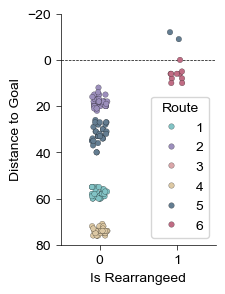

In [ ]:
def get_apvc(mouse: int) -> np.ndarray:
    with open(join(apvc_dir, f"{mouse}_apvc.pkl"), 'rb') as f:
        return pickle.load(f)

apvc = get_apvc(10275)

def get_last_prbin(mouse: int):
    apvc_data = get_apvc(mouse)

    maze_type = 1
    pre_retrieval_threshold = 0.2
    
    res = {
        "Session": [],
        "Route": [],
        "Distance to Goal": []
    }
    
    for s in range(6):
        for node, rt in zip(
            [1, 2, 6, 7, 8],
            [1, 2, 4, 5, 6]
        ):
            if mouse == 10275 and rt == 5 and s > 1:
                # This mouse was detected a map transition on Route 5, 
                # Map transition may cause the change of map identity
                # and will thus make the cross-session stability 
                # nonsense.
                continue
            
            if rt == 6 and session_convertor[mouse][s] >= 0:
                continue
                
            apvc_prev = apvc_data[CP_DSPs[maze_type][rt]-1, s, node]
            apvc_next = apvc_data[CP_DSPs[maze_type][rt]-1, s+1, node]
            apvc_prev[np.isnan(apvc_prev)] = 0
            apvc_next[np.isnan(apvc_next)] = 0
            idx = np.where(
                (apvc_prev <= pre_retrieval_threshold) &
                (apvc_next <= pre_retrieval_threshold)
            )[0]
            ## Continuously connected bins
            stop_idx = np.where(np.diff(idx) != 1)[0]
            #if stop_idx.shape[0] > 0:
            #    idx = idx[:stop_idx[0]+1]
            
            if idx.shape[0] == 0:
                continue
                    
            pre_retrieval_bins = CP_DSPs[maze_type][rt][idx]
            
            distance_to_goal = CP_DSPs[maze_type][rt].shape[0] - pre_retrieval_bins.shape[0]

            res['Session'].append(s)
            res['Distance to Goal'].append(distance_to_goal)
            res['Route'].append(rt)
    
    for key in res.keys():
        res[key] = np.asarray(res[key])
    return res

if exists(join(figdata, f"{code_id} [Proximity Effect].pkl")) == False:
    ProxEffect = {
        "MiceID": [],
        "Session": [],
        "Route": [],
        "Distance to Goal": [],
        "Is Rearrangeed": []
    }
    for mouse in tqdm([10212, 10224, 10227, 10232, 10275, 10276]):
        res = get_last_prbin(mouse)
        ProxEffect["MiceID"].append([mouse] * len(res['Session']))
        ProxEffect["Session"].append(res['Session'])
        ProxEffect["Route"].append(res['Route'])
        ProxEffect["Distance to Goal"].append(res['Distance to Goal'])
        is_rearranged = np.zeros(len(res['Session']), dtype=np.int64)
        is_rearranged[res['Route'] == 6] = 1
        if mouse == 10275:
            is_rearranged[res['Route'] == 5] = 1
            
        ProxEffect["Is Rearrangeed"].append(is_rearranged)
        
    for key in ProxEffect.keys():
        ProxEffect[key] = np.concatenate(ProxEffect[key])
        
    with open(join(figdata, f"{code_id} [Proximity Effect].pkl"), 'wb') as f:
        pickle.dump(ProxEffect, f)
        
    ProxEffect_df = pd.DataFrame(ProxEffect)
    ProxEffect_df.to_excel(join(figdata, f"{code_id} [Proximity Effect].xlsx"), index=False)
    print(len(ProxEffect_df))
else:
    with open(join(figdata, f"{code_id} [Proximity Effect].pkl"), 'rb') as f:
        ProxEffect = pickle.load(f)


fig = plt.figure(figsize=(2, 3))
ax = Clear_Axes(plt.axes(), close_spines=['top', 'right'], ifxticks=True, ifyticks=True)
ProxEffect['Distance to Goal'] -= 27
sns.stripplot(
    x="Is Rearrangeed",
    y="Distance to Goal",
    hue="Route",
    data=ProxEffect,
    hue_order=[1, 2, 3, 4, 5, 6],
    palette=DSPPalette[1:7],
    s=4,
    edgecolor='k',
    linewidth=0.15,
    ax=ax
)
ax.axhline(0, color='k', linestyle='--', linewidth=0.5)
ax.set_ylim(80, -20)
ax.set_xticks([0, 1])
plt.savefig(join(loc, f"{code_id} [Proximity Effect].svg"), dpi=600)
plt.savefig(join(loc, f"{code_id} [Proximity Effect].png"), dpi=600)
plt.show()